In [49]:
import numpy as np
import discretisedfield as df
import matplotlib.pyplot as plt
import matplotlib.animation as animation
import os 
from matplotlib.colors import hsv_to_rgb
import matplotlib.patches as patches
import matplotlib as mpl
from scripts.read_field import file_to_array, read_dir, draw_field, animate_field, spirality 
from scripts.mm.fit import fit
from scripts.mm.experiment import Experiment
import scripts.scientific 

mpl.rcParams.update(mpl.rcParamsDefault)

In [33]:
def topological_charge(m, dx=1.0, dy=1.0):
    dmdx = np.gradient(m, dx, axis=2)
    dmdy = np.gradient(m, dy, axis=1)
    cross = np.cross(dmdy, dmdx)
    density = np.sum(m * cross, axis=-1)
    Q = np.round(np.sum(density, axis=(1, 2)) * dx * dy / (4 * np.pi), 10)
    return Q

## Template

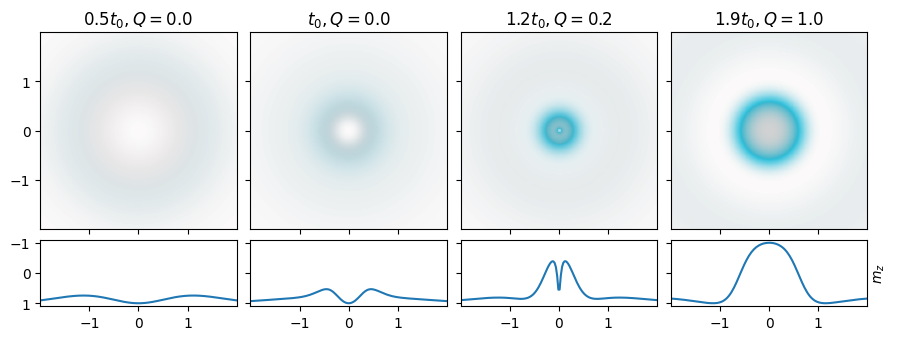

In [123]:
from cmap import Colormap
cmap = Colormap('colorcet:cet_cbtc2').to_mpl()
fig, axs = plt.subplots(2,4, figsize=(9,3.7), sharey='row', sharex='col',  gridspec_kw={'height_ratios': [3, 1]})
# fig, axs = plt.subplots(2,4, figsize=(9,3), sharey='row',  gridspec_kw={'height_ratios': [3, 1]})
fig.tight_layout()

data = np.concat([
    read_dir('./04-creation/skyrmion_system/drive-9-swing-start', delete_files=False, new_name=None, scaling=1e5),
    read_dir('./04-creation/skyrmion_system/drive-61-swing-end', delete_files=False, new_name=None, scaling=1e5),
    read_dir('./04-creation/skyrmion_system/drive-10-swing-end', delete_files=False, new_name=None, scaling=1e5)
])

middle = data.shape[1] // 2
cutoff = 200
charges = [round(Q,1) for Q in topological_charge(data)]
size = (data.shape[1] - 2 * cutoff) * 0.025 / 2
x = np.linspace(-size, size, data.shape[1] - 2 * cutoff)

axs[0][0].set_title(f"$0.5 t_0, Q={charges[2]}$", fontsize=12)
draw_field(axs[0][0], data[2], mode='spirality', cutoff=cutoff, spirality_contrast=10)
axs[1][0].plot(x, data[2, middle,cutoff:-cutoff, 2])

axs[0][1].set_title(f"$t_0, Q={charges[11]}$", fontsize=12)
draw_field(axs[0][1], data[11], mode='spirality', cutoff=cutoff, spirality_contrast=10)
axs[1][1].plot(x, data[11, middle,cutoff:-cutoff, 2])

axs[0][2].set_title(f"$1.2 t_0, Q={charges[15]}$", fontsize=12)
draw_field(axs[0][2], data[15], mode='spirality', cutoff=cutoff, spirality_contrast=10)
axs[1][2].plot(x, data[15, middle,cutoff:-cutoff, 2])

axs[0][3].set_title(f"$1.9 t_0, Q={charges[25]}$", fontsize=12)
draw_field(axs[0][3], data[25], mode='spirality', cutoff=cutoff, spirality_contrast=10)
axs[1][3].plot(x, data[25, middle,cutoff:-cutoff, 2])

for i, ax in enumerate(axs[0]):
    ax.set_xticks([-1,0,1])
    ax.set_yticks([-1,0,1])

axs[1][3].yaxis.set_label_position("right")
axs[1][3].set_ylabel("$m_z$")

for i, ax in enumerate(axs[1]):
    ax.set_yticks([1,0,-1])
    ax.yaxis.set_inverted(True)

plt.subplots_adjust(wspace=0.07, hspace=0.07, bottom=0.2)
plt.show()